# Finetuneando Stable Diffusion con LoRA

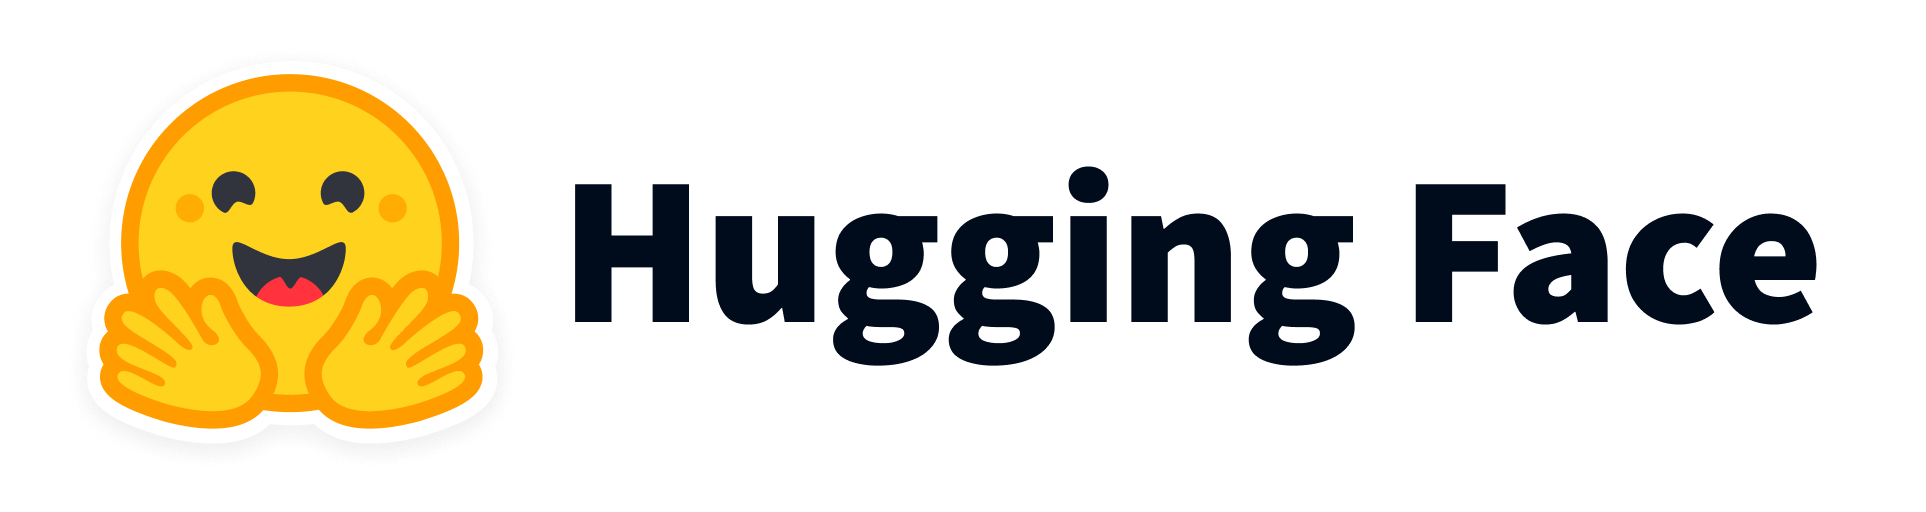

version 2.0 (LoRA)

# 0. Instalación de librerías

In [2]:
!pip install -qq diffusers datasets accelerate peft

# Colab trae preinstalada una version antigua de torchao que es incompatible con peft.
# peft solo la usa para cuantizacion (no la necesitamos), asi que la desinstalamos:
!pip uninstall -qq -y torchao

In [3]:
# import diffusers
# print(diffusers.__version__)

In [4]:
# Importamos las librerias necesarias:
from diffusers import StableDiffusionPipeline, DDPMScheduler
from diffusers import UNet2DConditionModel, AutoencoderKL, LMSDiscreteScheduler
from diffusers.utils import convert_state_dict_to_diffusers
from transformers import CLIPTextModel, CLIPTokenizer
from datasets import load_dataset
from accelerate import Accelerator
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import os
from tqdm import tqdm

In [5]:
# Vamos a utilizar GPU, necesaria para el entrenamiento:

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


# 1. Comportamiento original del modelo pre-entrenado

In [6]:
pretrained_model_name = "CompVis/stable-diffusion-v1-4" # Mismo modelo que vimos en clase (Stable Diffusion pre-entrenado)

# Cargamos un modelo pre-entrenado Stable Diffusion:
pipe = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name,
).to(device)

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

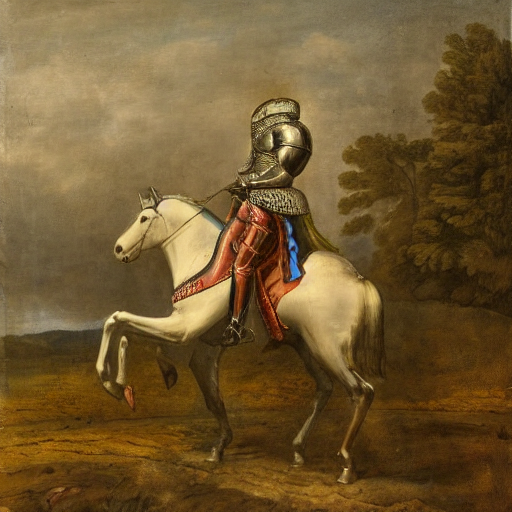

In [7]:
# Generamos una imagen con el modelo original:
prompt = "a knight riding a horse in front of a castle"

# Semilla: mismo prompt + misma semilla = misma imagen
seed = 42
generator = torch.Generator(device=device).manual_seed(seed) # generador de números aleatorios de PyTorch, semilla y para que funciona la GPU guardadndolo en la variable generator que se pasara a la 'tubería/pipeline'

image_antes = pipe(prompt, generator=generator).images[0]
image_antes.save("antes.png")
image_antes


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 2. Cargamos el dataset para finetunear

In [9]:
# Cargamos el dataset de ilustraciones de libros antiguos del ejercicio:
dataset_name = "gigant/oldbookillustrations"

dataset = load_dataset(dataset_name, split="train") # descarga el dataset de Hugging Face y los datasets se dividen en partes

# Vemos qué columnas tiene y cuántas imágenes:
print(dataset)

README.md:   0%|          | 0.00/8.54k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/4.03k [00:00<?, ?B/s]

data/train-00000-of-00013-c0326990f575de(…): reconstructing file:   0%|          |  0.00B /  628MB            

data/train-00000-of-00013-c0326990f575de(…): downloading bytes:           |  0.00B            

data/train-00001-of-00013-a511e1086f1718(…): reconstructing file:   0%|          |  0.00B /  439MB            

...

data/train-00011-of-00013-2e765ba2d2b351(…): downloading bytes:           |  0.00B            

data/train-00012-of-00013-cf490ec155e3b8(…): reconstructing file:   0%|          |  0.00B /  388MB            

data/train-00012-of-00013-cf490ec155e3b8(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4154 [00:00<?, ? examples/s]

Dataset({
    features: ['rawscan', '1600px', 'info_url', 'info_src', 'info_alt', 'artist_name', 'artist_birth_date', 'artist_death_date', 'artist_countries', 'book_title', 'book_authors', 'book_publishers', 'date_published', 'openlibrary-url', 'tags', 'illustration_source_name', 'illustration_source_url', 'illustration_subject', 'illustration_format', 'engravers', 'image_title', 'image_caption', 'image_description', 'rawscan_url', '1600px_url'],
    num_rows: 4154
})


Dataset({
    features: ['1600px', 'info_alt'],
    num_rows: 400
})
Tamaño de la imagen: (1121, 1600)
Descripción: They were changed into swans


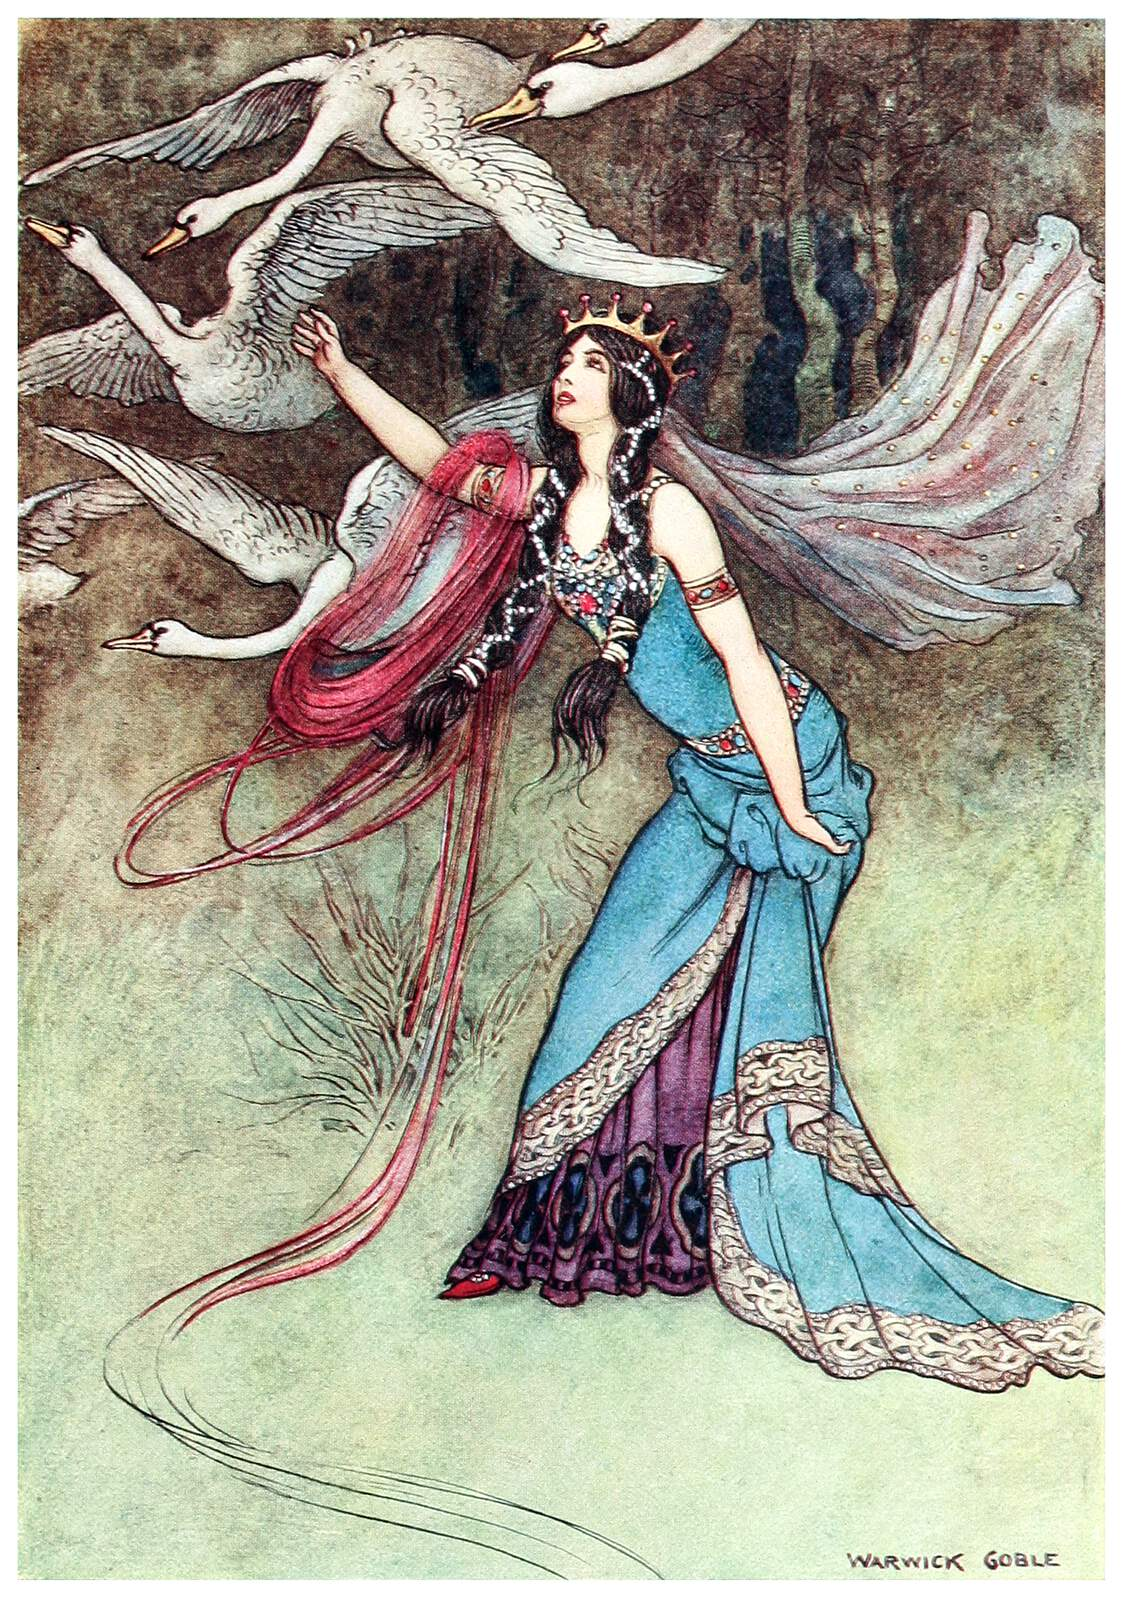

In [10]:
# Nos quedamos solo con la imagen y su descripción:
dataset = dataset.select_columns(["1600px", "info_alt"])

# Subconjunto aleatorio para que el entrenamiento quepa en Colab: baraja el dataset con la misma semilla
n_muestras = 400
dataset = dataset.shuffle(seed=seed).select(range(n_muestras))

print(dataset)

# Miramos un ejemplo:
ejemplo = dataset[0]
print("Tamaño de la imagen:", ejemplo["1600px"].size)
print("Descripción:", ejemplo["info_alt"])
ejemplo["1600px"]

In [11]:
# Resolución del modelo (indicada en su model card):
resolution = 512

image_transforms = transforms.Compose([
    transforms.Resize(resolution),        # el lado corto pasa a 512, mantiene la proporción
    transforms.CenterCrop(resolution),    # recorta el cuadrado central de 512x512
    transforms.ToTensor(),                # imagen -> tensor con valores 0..1
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),  # 0..1 -> -1..1
])

Tamaño del tensor: torch.Size([3, 512, 512])


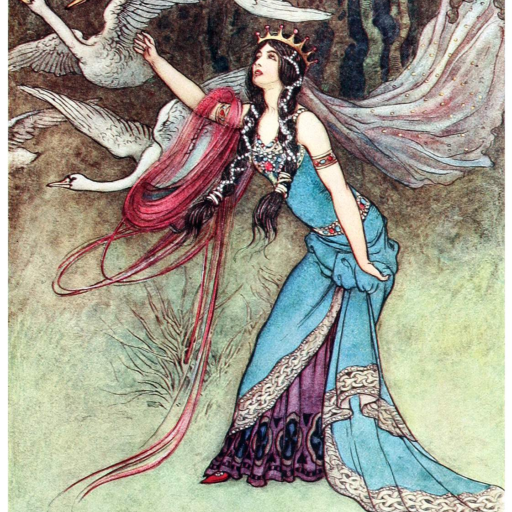

In [12]:
# Aplicamos las transformaciones a la imagen de ejemplo:
original_image = ejemplo["1600px"].convert("RGB")
transformed_image = image_transforms(original_image)

print("Tamaño del tensor:", transformed_image.shape)

# Para verla, deshacemos la normalización (-1..1 -> 0..1): IA
transformed_pil_image = transforms.ToPILImage()(transformed_image * 0.5 + 0.5)
transformed_pil_image

In [13]:
# Tamaño del lote (batch):
batch_size = 2  # no puede ser mayor por la memoria de la GPU

class Text2ImageDataset(Dataset): # la receta para una muestra. Dice: "cuando te pidan la muestra nº X, coge su imagen, pásala a RGB y transfórmala; coge su texto y conviértelo en tokens; devuelve las dos cosas juntas".
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        example = self.dataset[idx]
        image = image_transforms(example["1600px"].convert("RGB"))
        token = tokenizer(example["info_alt"], padding="max_length", truncation=True,
                          max_length=tokenizer.model_max_length, return_tensors="pt")
        return {
            "pixel_values": image,
            "input_ids": token.input_ids.squeeze(0),
            "attention_mask": token.attention_mask.squeeze(0),
        }

train_dataset = Text2ImageDataset(dataset)
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True) # la cinta transportadora. Usa esa receta para servir las muestras de 3 en 3, barajadas en cada época, hasta que se acaban las 400. Eso es una época.


# 3. Cargamos las componentes del modelo por separado

In [14]:
# Antes de cargar las componentes en la GPU, la vaciamos:
del pipe
torch.cuda.empty_cache()

In [15]:
# Tokenizador: Texto → números (tokens). Es el que usa tu Text2ImageDataset.
tokenizer = CLIPTokenizer.from_pretrained(pretrained_model_name, subfolder="tokenizer")

# Scheduler (controla el ruido): Decide cuánto ruido añadir a la imagen en cada paso
noise_scheduler = DDPMScheduler.from_pretrained(pretrained_model_name, subfolder="scheduler")

# Text Encoder (CLIP): Tokens → un vector que resume el significado del texto, el que guía a la UNet.
text_encoder = CLIPTextModel.from_pretrained(
    pretrained_model_name,
    subfolder="text_encoder",
).to(device)

# VAE (autoencoder): Imagen de 512×512 → "latente" de 64×64, mucho más pequeño. Así el modelo trabaja más rápido.
vae = AutoencoderKL.from_pretrained(
    pretrained_model_name,
    subfolder="vae",
).to(device)

# La UNet: La que aprende a quitar ruido guiada por el texto. Es el "cerebro" del modelo.
unet = UNet2DConditionModel.from_pretrained(
    pretrained_model_name,
    subfolder="unet",
).to(device)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

In [16]:
vae.eval()
text_encoder.eval()

for param in vae.parameters():
    param.requires_grad = False
for param in text_encoder.parameters():
    param.requires_grad = False

# 4. Añadimos la LoRA y preparamos el entrenamiento

En vez de finetunear los ~860M de parámetros de la UNet, usamos LoRA (Low-Rank Adaptation):

- Los pesos originales de la UNet se congelan.
- En las capas de atención (`to_q`, `to_k`, `to_v` y `to_out.0`) se añaden dos matrices pequeñas de bajo rango (`r`) cuyo producto se suma al peso original. Solo se entrenan esas matrices.
- Resultado: entrenamos <1% de los parámetros, necesitamos mucha menos memoria y el fichero final pesa unos MB en lugar de ~3.4 GB.
- La LoRA se carga encima del modelo base, así que se puede activar, desactivar o graduar su intensidad.

In [17]:
# 4.1 Hiperparámetros de la LoRA
lora_rank = 5     # tamaño de las matrices pequeñas (4-16 suele bastar)
lora_alpha = 5    # fuerza con la que se aplica la LoRA (se suele igualar al rango)

# 4.2 Configuración de la LoRA y la "inyectamos" en la UNet
lora_config = LoraConfig(
    r=lora_rank,
    lora_alpha=lora_alpha,
    init_lora_weights="gaussian",                          # valores iniciales aleatorios (normal)
    target_modules=["to_k", "to_q", "to_v", "to_out.0"],   # capas de atención
)
unet.add_adapter(lora_config, adapter_name="oldbooks")     # solo se puede ejecutar UNA vez por sesión

# 4.3 Comprobamos cuántos parámetros vamos a entrenar (solo los de la LoRA)
lora_params = [p for p in unet.parameters() if p.requires_grad]
n_lora = sum(p.numel() for p in lora_params)
n_total = sum(p.numel() for p in unet.parameters())
print(f"Parámetros entrenables (LoRA): {n_lora:,} de {n_total:,} ({100 * n_lora / n_total:.2f}%)")



Parámetros entrenables (LoRA): 996,480 de 860,517,444 (0.12%)


In [18]:
# 4.4 Optimizador: solo actualiza los parámetros de la LoRA
learning_rate = 1e-4                                            # tamaño del paso de aprendizaje
optimizer = torch.optim.AdamW(lora_params, lr=learning_rate)

# Accelerator: prepara modelo, optimizador y datos para la GPU
accelerator = Accelerator()
unet, optimizer, train_dataloader = accelerator.prepare(unet, optimizer, train_dataloader)
print(accelerator.device)

cuda


# 5. Proceso de entrenamiento: finetuning con LoRA

El bucle es idéntico al del finetuning completo (VAE-encode → añadir ruido → predecir ruido → MSE). La única diferencia es que el optimizador solo actualiza los pesos de la LoRA.

In [19]:
# La idea de fondo: si el modelo aprende a quitar el ruido de imágenes de este estilo,
# al generar desde ruido puro "dibujará" con ese estilo.

num_epochs = 5                     # nº de pasadas por las 400 imágenes (~9 min por época en una T4)

unet.train()                       # modo entrenamiento
for epoch in range(num_epochs):
    progress_bar = tqdm(train_dataloader, desc=f"Época {epoch}")

    for batch in progress_bar:

        # 1. Imagen -> espacio latente con el VAE (congelado, sin gradientes)
        with torch.no_grad():
            latents = vae.encode(batch["pixel_values"].to(accelerator.device)).latent_dist.sample()
            latents = latents * 0.18215          # factor de escala de SD 1.x

        # 2. Difusión hacia delante: añadimos ruido
        noise = torch.randn_like(latents)                                   # ruido aleatorio
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps,
                                  (latents.shape[0],), device=latents.device).long()  # cuánto ruido
        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        # 3. Codificamos el texto (info_alt)
        encoder_hidden_states = text_encoder(batch["input_ids"].to(accelerator.device))[0]

        # 4. La UNet (con LoRA) predice el ruido añadido
        noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample

        # 5. Error / función de pérdida y actualización (solo la LoRA)
        loss = torch.nn.functional.mse_loss(noise_pred, noise)
        accelerator.backward(loss)
        optimizer.step()
        optimizer.zero_grad()

        progress_bar.set_postfix(loss=loss.item())

Época 4: 100%|██████████| 200/200 [08:44<00:00,  2.62s/it, loss=0.27]


# 6. Generamos imágenes con la LoRA entrenada:

La UNet que acabamos de entrenar ya lleva la LoRA inyectada, así que la usamos directamente en el pipeline junto con el VAE, el text encoder y el tokenizer que ya teníamos cargados.

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Pipeline con LoRA listo


  0%|          | 0/50 [00:00<?, ?it/s]

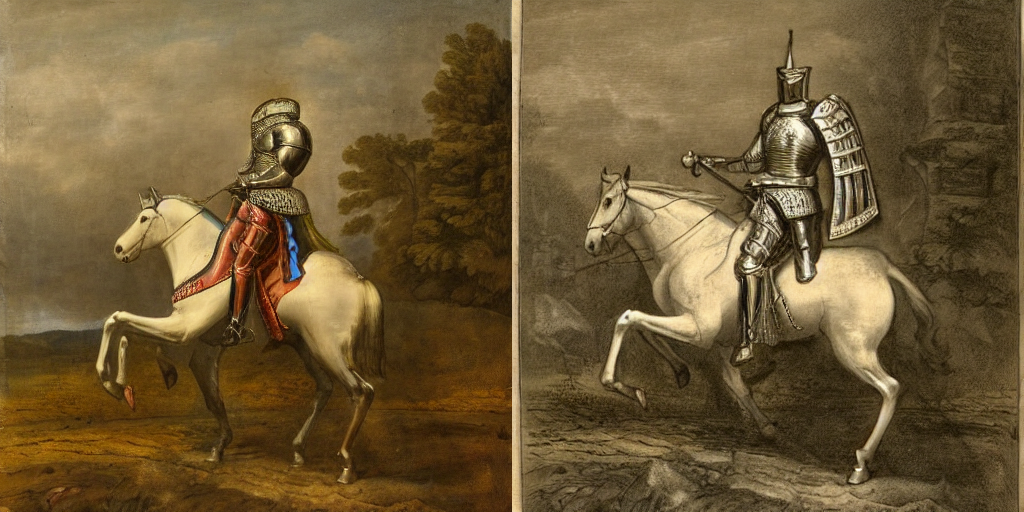

In [20]:
# 6.1 Recuperamos la UNet entrenada (con la LoRA dentro) y la ponemos en modo evaluación
unet = accelerator.unwrap_model(unet)   # le quitamos el "envoltorio" del Accelerator
unet.eval()                             # modo predicción (no entrenamiento)

# Montamos el pipeline reutilizando las piezas que ya tenemos en la GPU
pipe = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name,
    unet=unet,
    vae=vae,
    text_encoder=text_encoder,
    tokenizer=tokenizer,
).to(device)

pipe.set_adapters(["oldbooks"], adapter_weights=[1.0])   # intensidad de la LoRA: 0 = base, 1 = LoRA completa
print("Pipeline con LoRA listo")

# 6.2 Mismo prompt y misma semilla que la imagen "antes" -> comparación justa
prompt = "a knight riding a horse in front of a castle"
seed = 42                                                     # la misma de "antes"
generator = torch.Generator(device=device).manual_seed(seed)  # hay que recrearlo: el anterior ya se "gastó"

imagen_despues = pipe(prompt, generator=generator).images[0]
imagen_despues.save("despues.png")
imagen_despues

# 6.3 Juntamos "antes" y "después" en una sola imagen para la entrega
comparacion = Image.new("RGB", (1024, 512))     # lienzo de 2 imágenes de 512x512 en horizontal
comparacion.paste(image_antes, (0, 0))          # izquierda: modelo original
comparacion.paste(imagen_despues, (512, 0))     # derecha: modelo + LoRA
comparacion.save("antes_despues.png")
comparacion


# 7 Guardar los pesos LoRA:

Guardamos solo el modelo, lo que hemos entrenado que es la pequena parte que se puede reutilizar (quitar y poner como un componenete en modelos ya preentrenados).

Reutilizarlo es la gracia del LoRA

In [21]:

from peft.utils import get_peft_model_state_dict
from diffusers.utils import convert_state_dict_to_diffusers

unet_entrenado = accelerator.unwrap_model(unet)                                   # quita el "envoltorio" de Accelerator
lora_pesos = get_peft_model_state_dict(unet_entrenado, adapter_name="oldbooks")   # extrae SOLO las capas LoRA del adaptador "oldbooks"
lora_pesos = convert_state_dict_to_diffusers(lora_pesos)                          # renombra las claves al formato que entiende diffusers

StableDiffusionPipeline.save_lora_weights(
    save_directory="lora_oldbooks",
    unet_lora_layers=lora_pesos,
    safe_serialization=True,                                         # guarda en .safetensors (formato seguro y estándar)
)
!ls -lh lora_oldbooks

from google.colab import files
files.download("lora_oldbooks/pytorch_lora_weights.safetensors")   # copia de seguridad local del LoRA


total 3.9M
-rw------- 1 root root 3.9M Oct 26 16:00 pytorch_lora_weights.safetensors


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Conclusiones del ejercicio

Qué hemos hecho: adaptar Stable Diffusion v1.4, un modelo general, a un estilo concreto: las ilustraciones de libros antiguos. Para eso hemos entrenado solo un 0,1 % aproximado de sus parámetros.

Qué demuestra la imagen antes/después:

Antes: el modelo hace un óleo a color, que es su estilo "por defecto".
Después: con el mismo prompt y la misma semilla, sale un grabado en sepia con trazo de línea. Solo ha cambiado el estilo, no el contenido. El modelo sigue entendiendo "caballero, caballo, castillo" (incluso aparece el castillo, que antes no salía).

Conclusión: el LoRA ha aprendido el estilo del dataset este de hugging face sin que el modelo olvide lo que ya sabía.

Finetunning completo: toda la Unet, no entraría en Colab y serían unos 4gb, aparte de un riesgo alto de olvidar mientras que el Lora hacemos matrices más pequenas con pocos MB y que se queda congelado para reutilizar como un compoenente al finales de modelos ya preentrenados

# 8 Subir a Hugging Face

In [22]:
# 8.1 notebook_login
from huggingface_hub import notebook_login
notebook_login()

In [23]:
from huggingface_hub import upload_folder

upload_folder(
    repo_id="josanjd96/finetuned-sd-oldbookillustrations-PontIA",   # repo que creaste en la web
    folder_path="lora_oldbooks",                                     # carpeta con el .safetensors
    commit_message="LoRA estilo oldbookillustrations (5 épocas)",
)


CommitInfo(commit_url='https://huggingface.co/josanjd96/finetuned-sd-oldbookillustrations-PontIA/commit/5dd2cfe7ea123dd822e57793a5de8046141968bd', commit_message='LoRA estilo oldbookillustrations (5 épocas)', commit_description='', oid='5dd2cfe7ea123dd822e57793a5de8046141968bd', pr_url=None, repo_url=RepoUrl('https://huggingface.co/josanjd96/finetuned-sd-oldbookillustrations-PontIA', endpoint='https://huggingface.co', repo_type='model', repo_id='josanjd96/finetuned-sd-oldbookillustrations-PontIA'), pr_revision=None, pr_num=None)

In [24]:

# 8.2 repo_id en Hugging Face
from huggingface_hub import HfApi
api = HfApi()
repo_id = "josanjd96/finetuned-sd-oldbookillustrations-PontIA"

# 8.3 Crear el README (ficha del modelo) dentro de la carpeta del LoRA
readme = """---
base_model: CompVis/stable-diffusion-v1-4
library_name: diffusers
datasets:
- gigant/oldbookillustrations
tags:
- lora
- stable-diffusion
- text-to-image
---
# LoRA de Stable Diffusion v1.4 - ilustraciones de libros antiguos

Fine-tuning con LoRA (r=6, capas de atención to_k, to_q, to_v, to_out.0) de
CompVis/stable-diffusion-v1-4 con 400 imágenes del dataset gigant/oldbookillustrations
(columnas 1600px e info_alt), 5 épocas, batch 3, lr 1e-4.
"""
with open("lora_oldbooks/README.md", "w") as f:   # crea el fichero dentro de la carpeta lora_oldbooks
    f.write(readme)                                 # escribe el texto de arriba

!ls lora_oldbooks                                   # comprobación: deben salir README.md y pytorch_lora_weights.safetensors

# 8.4 subir toda la carpeta de google colab
from huggingface_hub import HfApi
api = HfApi()
repo_id = "josanjd96/finetuned-sd-oldbookillustrations-PontIA"



pytorch_lora_weights.safetensors  README.md


In [25]:
# 8.4 Subir toda la carpeta (LoRA + README) al repo de Hugging Face
api.upload_folder(
    repo_id=repo_id,                                  # definido en el 8.2
    folder_path="lora_oldbooks",                      # carpeta con el .safetensors y el README.md
    commit_message="Añadir README (ficha del modelo)",
)


No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/josanjd96/finetuned-sd-oldbookillustrations-PontIA/commit/5dd2cfe7ea123dd822e57793a5de8046141968bd', commit_message='Añadir README (ficha del modelo)', commit_description='', oid='5dd2cfe7ea123dd822e57793a5de8046141968bd', pr_url=None, repo_url=RepoUrl('https://huggingface.co/josanjd96/finetuned-sd-oldbookillustrations-PontIA', endpoint='https://huggingface.co', repo_type='model', repo_id='josanjd96/finetuned-sd-oldbookillustrations-PontIA'), pr_revision=None, pr_num=None)

# Bloque 9: añádelo al final del notebook

In [26]:
# 9.1 Cargar el modelo base y el LoRA desde Hugging Face
import torch
from diffusers import StableDiffusionPipeline

pipe_hf = StableDiffusionPipeline.from_pretrained(
    "CompVis/stable-diffusion-v1-4", torch_dtype=torch.float16     # modelo base (el mismo que entrenamos)
).to("cuda")
pipe_hf.load_lora_weights("josanjd96/finetuned-sd-oldbookillustrations-PontIA")   # descarga nuestro LoRA del repo


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

pytorch_lora_weights.safetensors: reconstructing file:   0%|          |  0.00B / 4.02MB            

pytorch_lora_weights.safetensors: downloading bytes:           |  0.00B            

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/50 [00:00<?, ?it/s]

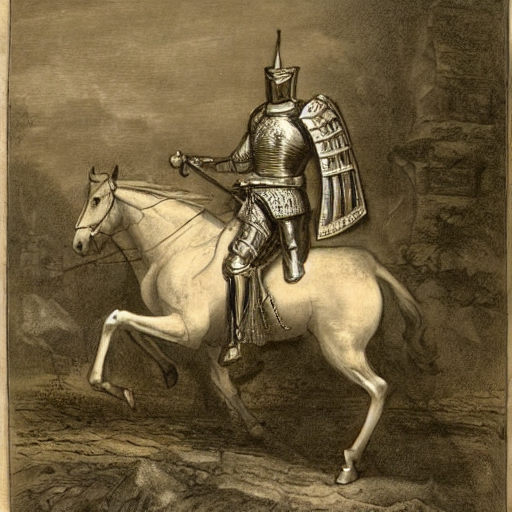

In [27]:
# 9.2 Generar la imagen con el mismo prompt y la misma semilla que antes/después
prompt = "a knight riding a horse in front of a castle"
generator = torch.Generator("cuda").manual_seed(42)

imagen_hf = pipe_hf(prompt, generator=generator).images[0]
imagen_hf.save("despues_desde_hf.png")
imagen_hf
